# Experiment 2: The eight queens problem
Generate-and-test over permutations against backtracking with pruning, n = 4 to 10.
Board representation: `board[c]` = row of the queen in column c.

In [1]:
import json, os, platform, subprocess, sys, time
from itertools import permutations
import matplotlib as mpl
import matplotlib.pyplot as plt

os.makedirs('figs', exist_ok=True)
mpl.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
                     'font.size': 10, 'axes.grid': True, 'grid.color': '0.88', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.4,
                     'legend.frameon': False, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
try:
    cpu = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
except Exception:
    cpu = platform.processor() or 'CPU'
print('Python', sys.version.split()[0], '|', platform.platform(), '|', cpu)
R = {'machine': f'{cpu}, {platform.platform()}, Python {sys.version.split()[0]}'}

Python 3.11.17 | macOS-27.0.1-arm64-arm-64bit | Apple M1


## 1. Generate and test

In [2]:
def conflicts(board):
    """Number of attacking pairs. Only rows and diagonals can clash: columns are distinct by construction."""
    n, bad = len(board), 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                bad += 1
    return bad

def generate_and_test(n):
    return [p for p in permutations(range(n)) if conflicts(p) == 0]

t0 = time.perf_counter(); gt8 = generate_and_test(8); print(len(gt8), 'solutions in', round(time.perf_counter() - t0, 4), 's')

92 solutions in 0.1121 s


## 2. Backtracking with pruning

In [3]:
def is_safe(board, col, row):
    """Can a queen sit at (row, col) given columns 0..col-1 are filled? Columns to the right are still empty."""
    for c in range(col):
        if board[c] == row or abs(board[c] - row) == abs(c - col):
            return False
    return True

def solve(n=8):
    sols, nodes = [], [0]
    def place(board, col):
        if col == n:
            sols.append(tuple(board)); return
        for row in range(n):
            nodes[0] += 1                       # every (col, row) tried is one node
            if is_safe(board, col, row):
                board[col] = row                # place
                place(board, col + 1)
                board[col] = -1                 # undo: the 'back' in backtracking
    place([-1] * n, 0)
    return sols, nodes[0]

bt8, nodes8 = solve(8)
print(len(bt8), 'solutions,', nodes8, 'nodes; same set as generate-and-test:', set(bt8) == set(gt8))
first = bt8[0]
print('first solution:', first)
for r in range(8):
    print(' '.join('Q' if first[c] == r else '.' for c in range(8)))
R['first_solution'] = list(first)

92 solutions, 15720 nodes; same set as generate-and-test: True
first solution: (0, 4, 7, 5, 2, 6, 1, 3)
Q . . . . . . .
. . . . . . Q .
. . . . Q . . .
. . . . . . . Q
. Q . . . . . .
. . . Q . . . .
. . . . . Q . .
. . Q . . . . .


## 3. Scaling, n = 4 to 10 (best of 3 timings for backtracking, 1 for generate-and-test at n = 10)

In [4]:
rows = []
print(f"{'n':>3} {'solutions':>10} {'nodes':>9} {'backtrack s':>12} {'generate s':>11} same?")
for n in range(4, 11):
    tb = []
    for _ in range(3):
        t0 = time.perf_counter(); s, nd = solve(n); tb.append(time.perf_counter() - t0)
    reps = 3 if n < 10 else 1
    tg = []
    for _ in range(reps):
        t0 = time.perf_counter(); g = generate_and_test(n); tg.append(time.perf_counter() - t0)
    same = set(s) == set(g)
    rows.append(dict(n=n, solutions=len(s), nodes=nd, t_bt=min(tb), t_gt=min(tg), gt_solutions=len(g), same=same))
    print(f'{n:>3} {len(s):>10} {nd:>9} {min(tb):>12.4f} {min(tg):>11.4f} {same}')
R['table'] = rows

  n  solutions     nodes  backtrack s  generate s same?
  4          2        60       0.0000      0.0000 True
  5         10       220       0.0001      0.0002 True
  6          4       894       0.0002      0.0013 True
  7         40      3584       0.0010      0.0115 True


  8         92     15720       0.0047      0.1109 True


  9        352     72378       0.0231      1.2024 True


 10        724    348150       0.1180     14.8246 True


## 4. Symmetry: fundamental solutions for n = 8

In [5]:
def transforms(b):
    """All 8 images of a board under the symmetries of the square (as tuples)."""
    n = len(b); pts = [(c, b[c]) for c in range(n)]
    out = set()
    for k in range(4):
        for flip in (False, True):
            q = pts
            for _ in range(k):
                q = [(r, n - 1 - c) for c, r in q]          # rotate 90 degrees
            if flip:
                q = [(n - 1 - c, r) for c, r in q]          # mirror
            out.add(tuple(r for c, r in sorted(q)))
    return out

classes, seen = [], set()
for s in bt8:
    if s not in seen:
        imgs = transforms(s); seen |= imgs; classes.append(len(imgs))
print(len(classes), 'fundamental solutions; class sizes:', sorted(classes))
R['fundamental'] = dict(count=len(classes), sizes=sorted(classes))

12 fundamental solutions; class sizes: [4, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8]


## 5. Viva Q2: which bug gives 2113 solutions? Drop abs() so only one diagonal is checked.

In [6]:
def is_safe_one_diagonal(board, col, row):
    for c in range(col):
        if board[c] == row or (board[c] - row) == abs(c - col):   # BUG: abs() missing on the left
            return False
    return True

_saved = is_safe
is_safe = is_safe_one_diagonal
buggy, _ = solve(8)
is_safe = _saved
print('one-diagonal bug ->', len(buggy), 'solutions')
R['bug_one_diagonal'] = len(buggy)

one-diagonal bug -> 2113 solutions


## 6. Figures

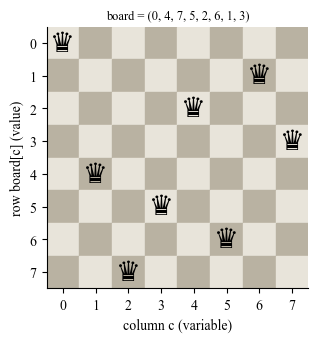

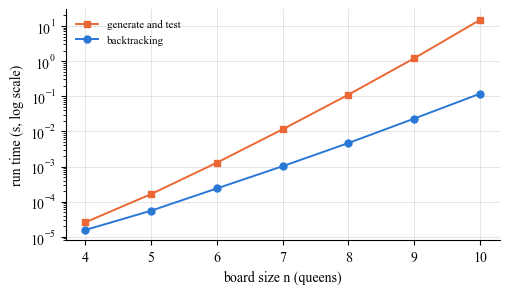

In [7]:
fig, ax = plt.subplots(figsize=(3.4, 3.4))
for r in range(8):
    for c in range(8):
        ax.add_patch(plt.Rectangle((c, r), 1, 1, color='#e8e4da' if (r + c) % 2 == 0 else '#b9b2a2'))
for c, r in enumerate(first):
    ax.text(c + 0.5, r + 0.5, '♛', ha='center', va='center', fontsize=20, color='k',
            fontfamily='DejaVu Sans')
ax.set_xlim(0, 8); ax.set_ylim(8, 0); ax.set_aspect('equal'); ax.grid(False)
ax.set_xticks([i + 0.5 for i in range(8)]); ax.set_xticklabels(range(8))
ax.set_yticks([i + 0.5 for i in range(8)]); ax.set_yticklabels(range(8))
ax.set_xlabel('column c (variable)'); ax.set_ylabel('row board[c] (value)')
ax.set_title(f'board = {first}', fontsize=9)
fig.savefig('figs/fig2_1_board.png'); plt.show()

fig, ax = plt.subplots(figsize=(5.6, 3.0))
ns = [r['n'] for r in rows]
ax.semilogy(ns, [r['t_gt'] for r in rows], 's-', color=C[1], ms=5, label='generate and test')
ax.semilogy(ns, [r['t_bt'] for r in rows], 'o-', color=C[0], ms=5, label='backtracking')
ax.set_xlabel('board size n (queens)'); ax.set_ylabel('run time (s, log scale)')
ax.legend(loc='upper left', fontsize=8)
fig.savefig('figs/fig2_2_runtime.png'); plt.show()

In [8]:
with open('results.json', 'w') as fh:
    json.dump(R, fh, indent=1)
print('saved results.json')

saved results.json
